In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
from pathlib import Path

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sys.path.append(str(Path().resolve().parent / "src"))

from model_sampler import DDIMSampler
from results import ModelResults, ModelComparison, build_dataset, METRICS_PRED, METRICS_PLAN, METRICS_PLAN_EXTENDED, is_higher_better, get_metric_abbr, get_metric_label

In [3]:
dataset = build_dataset('test')

In [4]:
unet_baseline = ModelResults('107-deeplabv3plus', 'unet', 199, 'test', dataset)
baseline = ModelResults('112-beamdiff-bf16', 'ddpm-1000', 199, 'test', dataset)

In [22]:
ddpm_1024 = ModelResults('119-t-1024', 'ddpm-1024', 199, 'test', dataset)
ddpm_512 = ModelResults('119-t-1024', 'ddpm-512', 99, 'test', dataset, 'progressive-v1', '0-1024-to-512')
ddpm_256 = ModelResults('119-t-1024', 'ddpm-256', 99, 'test', dataset, 'progressive-v1', '1-512-to-256')
ddpm_128 = ModelResults('119-t-1024', 'ddpm-128', 99, 'test', dataset, 'progressive-v1', '2-256-to-128')
ddpm_64 = ModelResults('119-t-1024', 'ddpm-64', 99, 'test', dataset, 'progressive-v1', '3-128-to-64')
ddpm_32 = ModelResults('119-t-1024', 'ddpm-32', 99, 'test', dataset, 'progressive-v1', '4-64-to-32')
ddpm_16 = ModelResults('119-t-1024', 'ddpm-16', 99, 'test', dataset, 'progressive-v1', '5-32-to-16')
ddpm_8 = ModelResults('119-t-1024', 'ddpm-8', 99, 'test', dataset, 'progressive-v1', '6-16-to-8')
ddpm_4 = ModelResults('119-t-1024', 'ddpm-4', 99, 'test', dataset, 'progressive-v1', '7-8-to-4')
ddpm_2 = ModelResults('119-t-1024', 'ddpm-2', 99, 'test', dataset, 'progressive-v1', '8-4-to-2')

In [23]:
ddim_1024 = ModelResults('119-t-1024', 'ddim-1024', 199, 'test', dataset)
ddim_512 = ModelResults('119-t-1024', 'ddim-512', 99, 'test', dataset, 'progressive-v1', '0-1024-to-512')
ddim_256 = ModelResults('119-t-1024', 'ddim-256', 99, 'test', dataset, 'progressive-v1', '1-512-to-256')
ddim_128 = ModelResults('119-t-1024', 'ddim-128', 99, 'test', dataset, 'progressive-v1', '2-256-to-128')
ddim_64 = ModelResults('119-t-1024', 'ddim-64', 99, 'test', dataset, 'progressive-v1', '3-128-to-64')
ddim_32 = ModelResults('119-t-1024', 'ddim-32', 99, 'test', dataset, 'progressive-v1', '4-64-to-32')
ddim_16 = ModelResults('119-t-1024', 'ddim-16', 99, 'test', dataset, 'progressive-v1', '5-32-to-16')
ddim_8 = ModelResults('119-t-1024', 'ddim-8', 99, 'test', dataset, 'progressive-v1', '6-16-to-8')
ddim_4 = ModelResults('119-t-1024', 'ddim-4', 99, 'test', dataset, 'progressive-v1', '7-8-to-4')
ddim_2 = ModelResults('119-t-1024', 'ddim-2', 99, 'test', dataset, 'progressive-v1', '8-4-to-2')

In [24]:
ddpm_comparison = ModelComparison(
  [ddpm_1024, ddpm_512, ddpm_256, ddpm_128, ddpm_64, ddpm_32, ddpm_16, ddpm_8, ddpm_4, ddpm_2],
  ['T=1024', 'T=512', 'T=256', 'T=128', 'T=64', 'T=32',  'T=16', 'T=8', 'T=4', 'T=2']
)

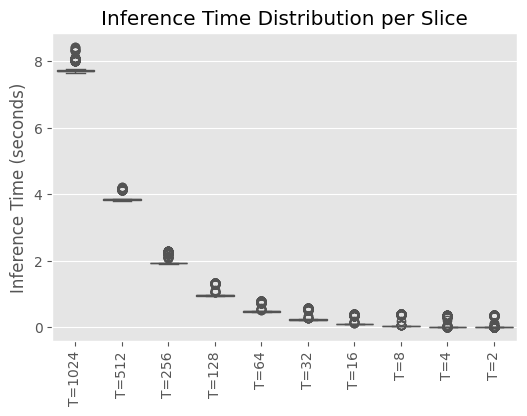

In [25]:
_ = ddpm_comparison.plot_inference_times('slice', 'seconds')

/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/src/results.py:1041: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title='')
/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/src/results.py:1041: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title='')
/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/src/results.py:1041: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title='')
/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/src/results.py:1041: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore 

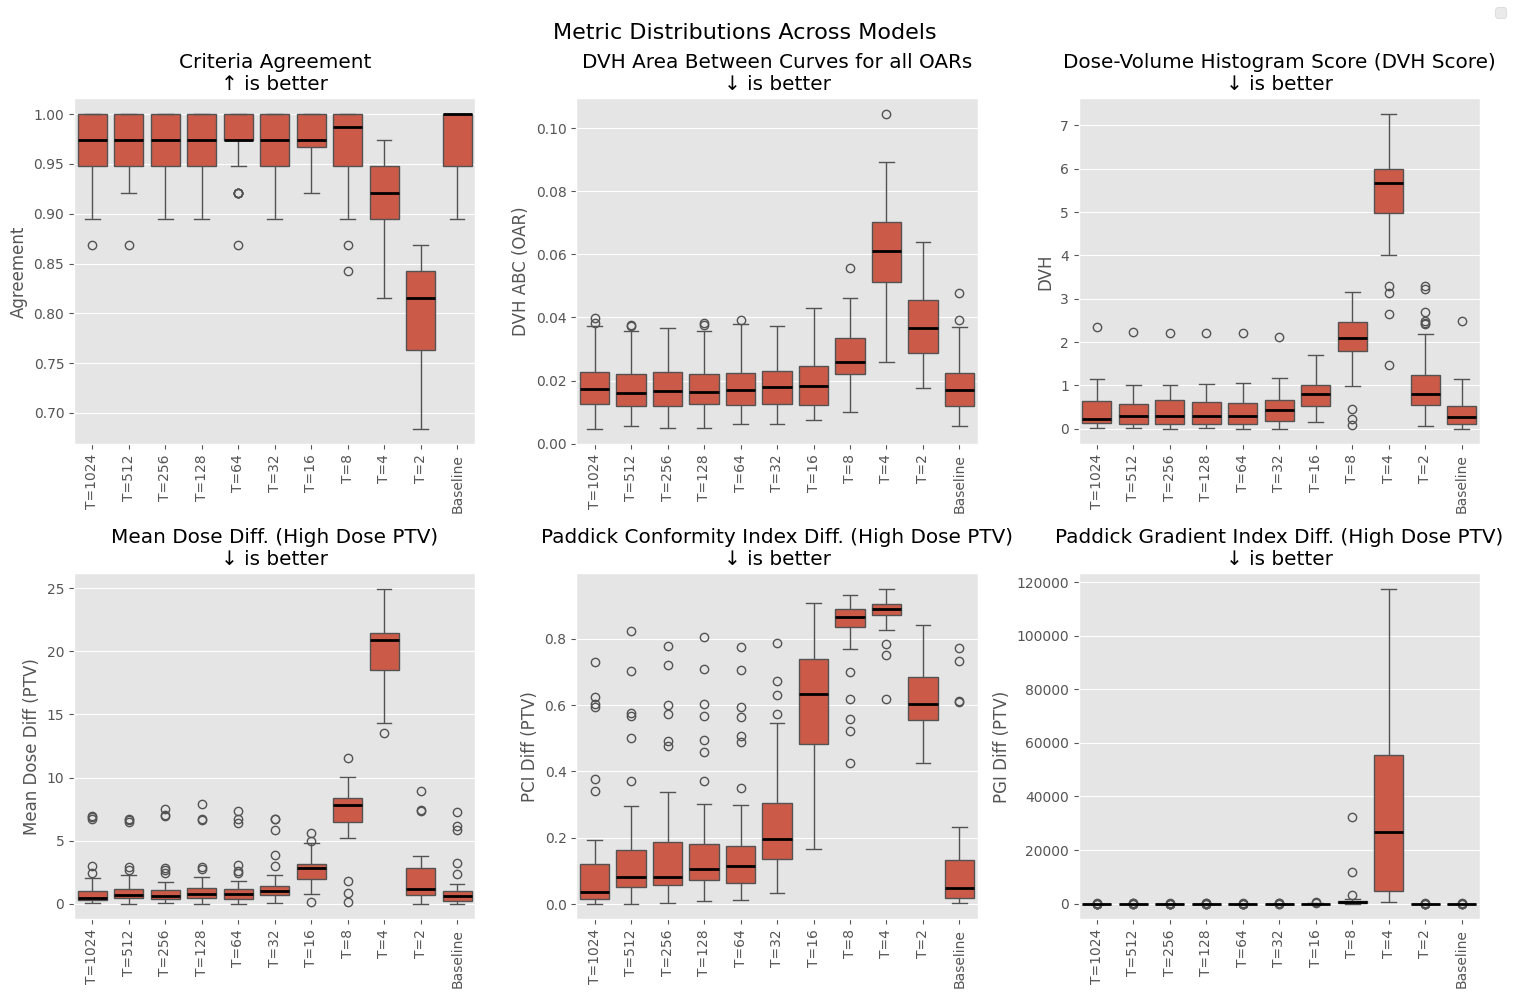

In [26]:
_ = (ddpm_comparison + ModelComparison([baseline], ['Baseline'])).plot_metric_distributions(METRICS_PRED)

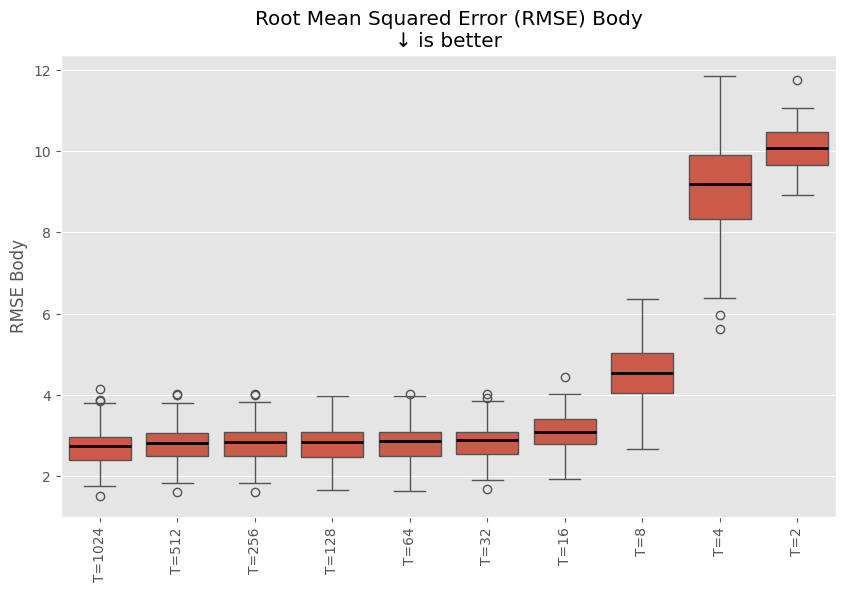

In [27]:
_ = ddpm_comparison.plot_metric_distribution('vol_rmse_body')

## DDIM

In [16]:
ddim_comparison = ModelComparison(
  [ddim_1024, ddim_512, ddim_256, ddim_128, ddim_64, ddim_32, ddim_16, ddim_8, ddim_4, ddim_2],
  ['T=1024', 'T=512', 'T=256', 'T=128', 'T=64', 'T=32',  'T=16', 'T=8', 'T=4', 'T=2']
)

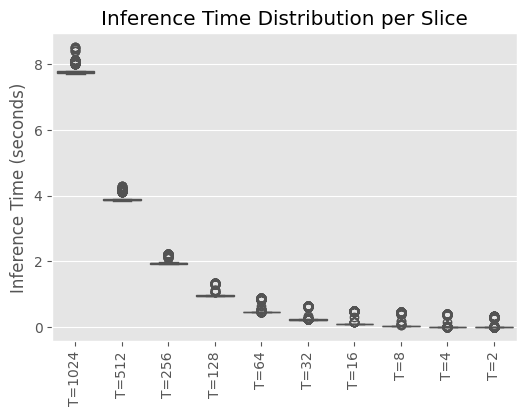

In [17]:
_ = ddim_comparison.plot_inference_times('slice', 'seconds')

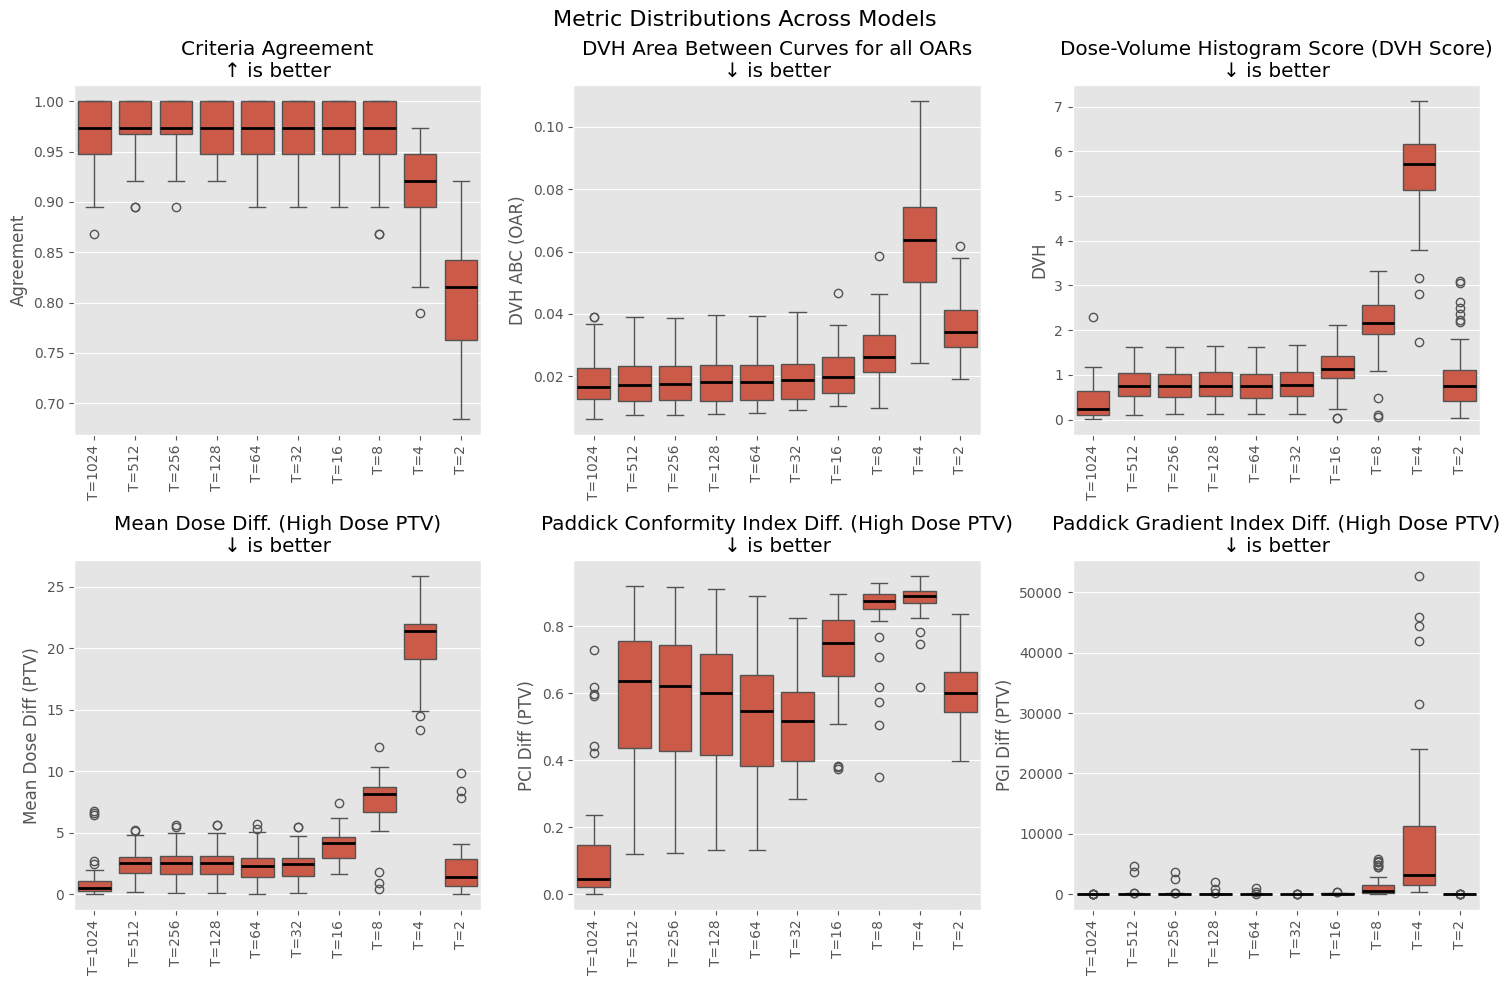

In [19]:
_ = ddim_comparison.plot_metric_distributions(METRICS_PRED)

In [20]:
comparison = ModelComparison(
  [ddpm_1024, ddpm_512, ddpm_256, ddpm_128, ddpm_64, ddpm_32, ddpm_16, ddpm_8, ddpm_4, ddpm_2,
   ddim_1024, ddim_512, ddim_256, ddim_128, ddim_64, ddim_32, ddim_16, ddim_8, ddim_4, ddim_2],
  ['DDPM T=1024', 'DDPM T=512', 'DDPM T=256', 'DDPM T=128', 'DDPM T=64', 'DDPM T=32',  'DDPM T=16', 'DDPM T=8', 'DDPM T=4', 'DDPM T=2',
   'DDIM T=1024', 'DDIM T=512', 'DDIM T=256', 'DDIM T=128', 'DDIM T=64', 'DDIM T=32',  'DDIM T=16', 'DDIM T=8', 'DDIM T=4', 'DDIM T=2']
)

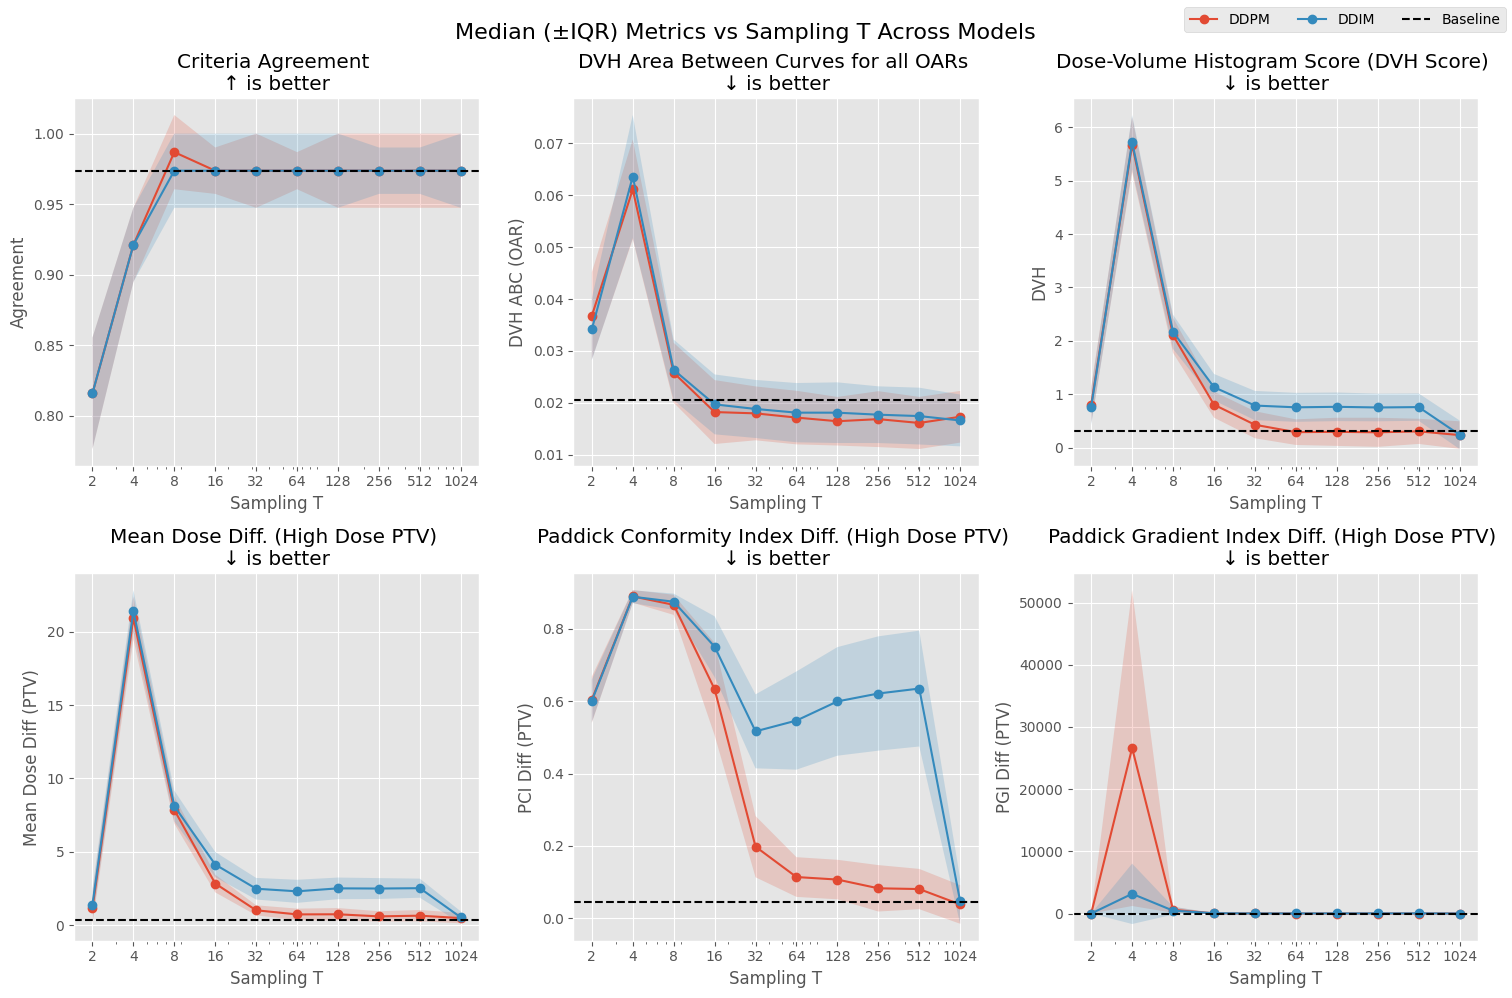

In [21]:
_ = comparison.plot_quality_over_T(METRICS_PRED, agg='median', baseline=unet_baseline)